In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv("earthquakes-2026-10-14_21-39-07_+0800.tsv",sep="\t") #一开始报错，没有注意文件时tsv格式：使用的文件是 .tsv 格式，字段之间由制表符分隔，而不是普通CSV文件常用的逗号。因此，读取文件时需要设置 sep="\t"。
df.info()
df = df.loc[df["Year"].notna()].copy() #删除没有年份的非地震记录方便后续整理，相当于课上提到的数据清洗
df["Year"] = df["Year"].astype(int) #把年份后面的“.0”去掉，便于年份分组，同时整数才可以生成连续的数
print("地震记录数：", len(df))
print("国家或地区数：", df["Country"].nunique())
print("年份范围：", df["Year"].min(), "-", df["Year"].max())

<class 'pandas.DataFrame'>
RangeIndex: 6698 entries, 0 to 6697
Data columns (total 49 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Search Parameters                   1 non-null      str    
 1   Id                                  6697 non-null   float64
 2   Year                                6697 non-null   float64
 3   Mo                                  6293 non-null   float64
 4   Dy                                  6122 non-null   float64
 5   Hr                                  4580 non-null   float64
 6   Mn                                  4357 non-null   float64
 7   Sec                                 3864 non-null   float64
 8   Tsu                                 2124 non-null   float64
 9   Vol                                 82 non-null     float64
 10  Country                             6697 non-null   str    
 11  Area                                335 non-null    st

In [11]:
#1.1计算自公元前 2150 年以来各国因地震造成的死亡总人数，然后输出死亡人数排名前 20 的国家及其死亡总人数。
#按国家分组
deaths_by_country = (df.groupby("Country")["Deaths"].sum(min_count=1).sort_values(ascending=False))
# 提取排名前20的国家
top20_deaths = deaths_by_country.head(20)
print(top20_deaths)

Country
CHINA           2139209.0
TURKEY          1199720.0
IRAN            1014453.0
ITALY            492236.0
SYRIA            419826.0
HAITI            323484.0
AZERBAIJAN       319251.0
JAPAN            242516.0
ARMENIA          177890.0
PAKISTAN         145085.0
IRAQ             136200.0
ECUADOR          135496.0
TURKMENISTAN     117412.0
PERU             102309.0
ISRAEL            93388.0
PORTUGAL          83572.0
GREECE            81162.0
CHILE             64277.0
INDIA             63507.0
TAIWAN            57154.0
Name: Deaths, dtype: float64


Ms > 3.0 的地震记录总数： 3101
至少有一条符合条件记录的年份数： 511


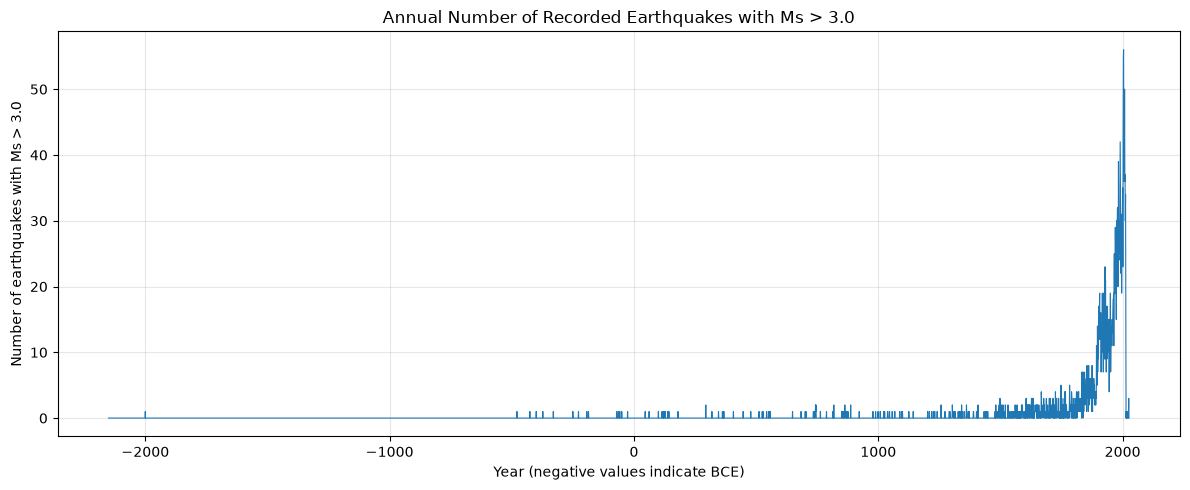

In [12]:
#1.2计算全球每年震级大于3.0的地震总数（使用Ms列作为震级），然后绘制时间序列图。你观察到任何趋势吗？解释原因或说明为何没有趋势。
#筛选条件为Ms>3.0。如果某一年没有符合这个条件的，groupby() 不会自动生成这一年的结果。因此，需要使用 reindex() 补齐完整年份范围，并将缺失的年度计数填为 0。（←这一部分是AI给的思路）
eq_ms3 = df.loc[df["Ms"] > 3.0].copy()

# 按年份统计每年的地震记录数
annual_counts = eq_ms3.groupby("Year").size()

# 构建完整年份序列：公元前2150年至2026年
all_years = pd.Index(range(df["Year"].min(), df["Year"].max() + 1),name="Year")
# 补齐没有符合条件记录的年份
annual_counts = annual_counts.reindex(all_years, fill_value=0)
# 输出统计结果
print("Ms > 3.0 的地震记录总数：", len(eq_ms3))
print("至少有一条符合条件记录的年份数：",
      (annual_counts > 0).sum())
# 绘制时间序列图：这个检索了一下怎么绘制。。
plt.figure(figsize=(12, 5))
plt.plot(annual_counts.index,annual_counts.values,linewidth=0.8)
plt.xlabel("Year (negative values indicate BCE)")
plt.ylabel("Number of earthquakes with Ms > 3.0")
plt.title("Annual Number of Recorded Earthquakes with Ms > 3.0")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("earthquake_annual_Ms_gt3_timeseries.png",dpi=200)
plt.show()


In [17]:
#1.3编写一个函数 CountEq_LargestEq，该函数应返回：(a) 自公元前2150年以来某给定国家发生的地震总数，以及 (b) 该国有史以来最大地震的日期和地点。将 CountEq_LargestEq 应用于文件中的每个国家，并将结果按降序排列报告。
def format_date(row):
    """将年份、月份和日期格式化为可读字符串。"""
    year = int(row["Year"])
    if year < 0:
        date = f"公元前{abs(year)}年"
    else:
        date = f"{year}年"
    if pd.notna(row["Mo"]):
        date += f"{int(row['Mo']):02d}月"
        if pd.notna(row["Dy"]):
            date += f"{int(row['Dy']):02d}日"
    return date

def CountEq_LargestEq(country, data=df):
    """
    返回：
    1. 该国地震记录总数
    2. 最大地震日期
    3. 最大地震地点

    使用 Ms 字段确定最大地震。
    """
    # 筛选给定国家
    sub = data.loc[data["Country"].eq(country)]
    # 统计地震记录条数
    n_events = len(sub)
    # 仅保留具有震级数据的记录
    valid = sub.loc[sub["Ms"].notna()]
    # 如果该国没有可用震级，则无法确定最大地震
    if valid.empty:
        return n_events, None, None
    # 找出最大震级
    max_ms = valid["Ms"].max()
    # 找出对应的地震记录
    largest = valid.loc[valid["Ms"].eq(max_ms)].sort_values(["Year", "Mo", "Dy"],na_position="last").iloc[0]
    # 提取日期与地点
    date = format_date(largest)

    location = (largest["Location Name"]
        if pd.notna(largest["Location Name"])
        else "地点未知"
    )

    return n_events, date, location

In [23]:
results = []
# 遍历所有国家
for country in df["Country"].dropna().unique():
    n_events, date, location = CountEq_LargestEq(
        country, df
    )

    # 额外记录最大震级，便于结果核查
    largest_ms = df.loc[df["Country"].eq(country), "Ms"].max()
    results.append({
        "Country": country,
        "Earthquake_Count": n_events,
        "Largest_Ms": largest_ms,
        "Largest_Date": date,
        "Largest_Location": location
    })

# 转换为 DataFrame
country_results = pd.DataFrame(results)
# 按地震记录数降序排列
country_results = country_results.sort_values(by=["Earthquake_Count", "Country"],ascending=[False, True]).reset_index(drop=True)
# 添加排名
country_results.insert(0, "Rank", np.arange(1, len(country_results) + 1))
print(country_results.to_string(index=False))
# 保存全部国家的统计结果
country_results.to_csv(
    "earthquake_country_statistics.csv",
    index=False,
    encoding="utf-8-sig"
)

 Rank                                      Country  Earthquake_Count  Largest_Ms Largest_Date                                     Largest_Location
    1                                        CHINA               626         8.6  1668年07月25日                            CHINA:  SHANDONG PROVINCE
    2                                        JAPAN               429         8.6  2011年03月11日                                       JAPAN:  HONSHU
    3                                    INDONESIA               427         8.8  2004年12月26日          INDONESIA:  SUMATRA:  ACEH:  OFF WEST COAST
    4                                         IRAN               385         7.9   856年12月22日                                IRAN:  DAMGHAN, QUMIS
    5                                       TURKEY               359         7.8  1939年12月26日                                    TURKEY:  ERZINCAN
    6                                        ITALY               338         7.5  1915年01月13日                   ITALY:

In [25]:
#第二题
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
met = pd.read_csv("Baoan_Weather_1998_2022.csv")
met.info()

C:\Users\22521\AppData\Local\Temp\ipykernel_122396\1719925296.py:4: DtypeWarning: Columns (0: CALL_SIGN, 1: AA3, 2: AG1, 3: AJ1, 4: AW1, 5: AZ1, 6: CALL_SIGN.1, 7: GA5, 8: GE1, 9: HL1, 10: IA2, 11: KA2, 12: ME1, 13: MW3, 14: OA1, 15: OD1, 16: OD2, 17: SA1, 18: UA1, 19: UG1) have mixed types. Specify dtype option on import or set low_memory=False.
  met = pd.read_csv("Baoan_Weather_1998_2022.csv")


<class 'pandas.DataFrame'>
RangeIndex: 235674 entries, 0 to 235673
Data columns (total 54 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   STATION            235674 non-null  int64  
 1   DATE               235674 non-null  str    
 2   SOURCE             235674 non-null  int64  
 3   REPORT_TYPE        235674 non-null  str    
 4   CALL_SIGN          235674 non-null  object 
 5   QUALITY_CONTROL    235674 non-null  str    
 6   AA1                24482 non-null   str    
 7   AA2                5923 non-null    str    
 8   AA3                3207 non-null    str    
 9   AG1                7307 non-null    str    
 10  AJ1                679 non-null     str    
 11  AW1                3 non-null       str    
 12  AY1                15557 non-null   str    
 13  AY2                9200 non-null    str    
 14  AZ1                3 non-null       str    
 15  CALL_SIGN.1        235674 non-null  object 
 16  CIG          

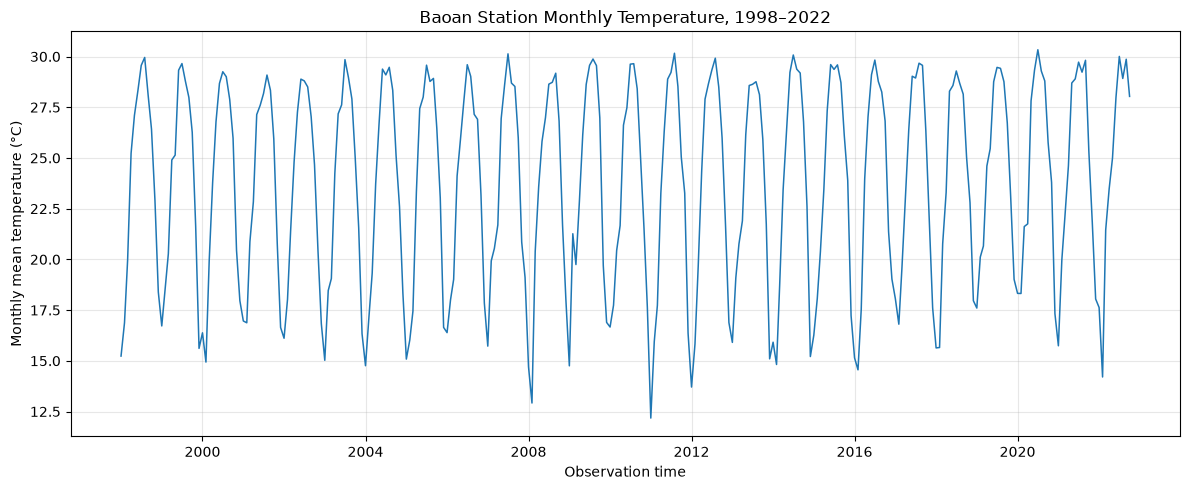

In [29]:
#对数据进行预处理，TMP是纯文本，包括原始气温值和质量代码（问了AI）。需要先提取温度和质量代码才可以进行有效数值计算
parts = met['TMP'].astype('string').str.extract(
    r'^([+-]\d{4}),([0-9A-Z])$'
)#查了课程内容、网络信息。该方法通过正则表达式从字符串中提取指定内容。正则表达式可以拆开理解：^表示字符串开始；[+-]表示一个正号或负号；\d{4}表示连续四个数字；，匹配逗号；$字符串结束；（...）捕获匹配内容
#将数据转换为数值类型
met['TMP_raw'] = pd.to_numeric(parts[0],errors='coerce')#遇到无法转换的数据时，不抛出错误，将其转化为NaN
met['TMP_quality'] = parts[1]
met['Temperature_C'] = met['TMP_raw'] / 10 #原始温度转化为摄氏度
#将日期字符串转换为pandas的日期时间类型
met['DATE'] = pd.to_datetime( met['DATE'],errors='coerce')


#根据质量代码筛选有效气温
accepted_quality = {'0', '1', '4', '5', '9','A', 'C', 'I', 'M', 'P', 'R', 'U'}
valid = (met['DATE'].between('1998-01-01','2022-12-31 23:59:59')
    & met['TMP_raw'].between(-932, 618)
    & met['TMP_quality'].isin(accepted_quality)
)#判断日期和气温是否在指定范围内

met_clean = met.loc[valid].copy()



#使用groupby计算月平均气温
met_clean['Month'] = (met_clean['DATE'].dt.to_period('M'))#按照月份创建周期，M表示月
monthly = (met_clean.groupby('Month')['Temperature_C'].agg(['mean', 'size']))
monthly.columns = ['MonthlyMean_C', 'Count']
monthly = monthly.reset_index()
monthly['Date'] = monthly['Month'].dt.to_timestamp()
monthly.to_csv(
    'Baoan_monthly_temperature_1998_2022.csv',
    index=False
)

#绘制月平均气温时间序列
plt.figure(figsize=(12, 5))

plt.plot(
    monthly['Date'],
    monthly['MonthlyMean_C'],
    lw=1.1
)

plt.xlabel('Observation time')
plt.ylabel('Monthly mean temperature (°C)')
plt.title('Baoan Station Monthly Temperature, 1998–2022')

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    'Baoan_monthly_temperature_timeseries.png',
    dpi=200
)

plt.show()

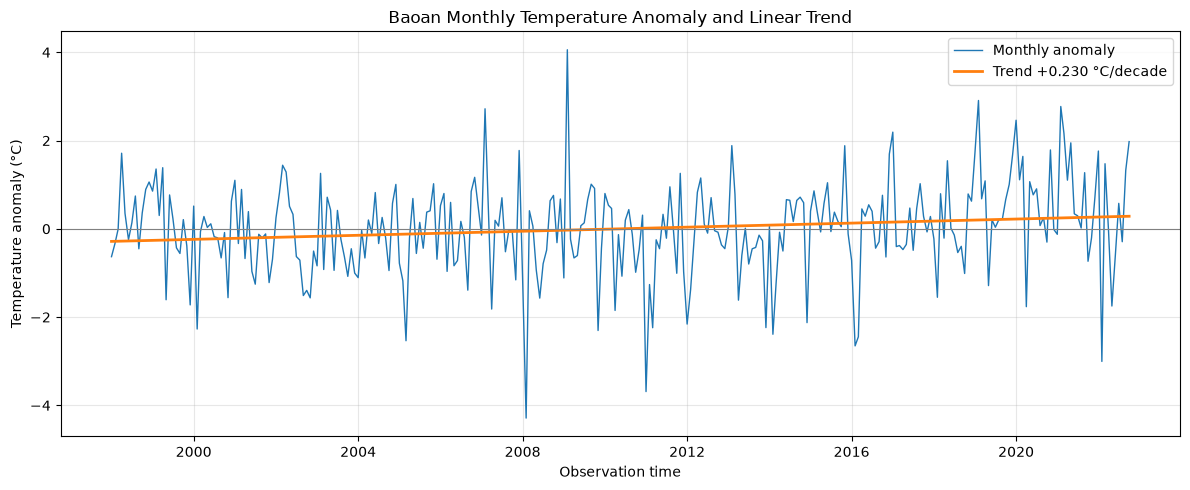

In [33]:
#计算月气温距平。指的是某个月实际平均气温与该日历月份多年平均气温之间的差值。
#按照monthnumber分组，得到1-12月份编号。分别计算各月份的平均气温。得到一组多年平均月气温作为参考基准。
monthly['MonthNumber'] = monthly['Date'].dt.month
climatology = (
    monthly.groupby('MonthNumber')['MonthlyMean_C'].mean()
)
#将每一条月记录对应的月份编号映射为该月份的多年平均温度
monthly['Anomaly_C'] = (
    monthly['MonthlyMean_C']
    - monthly['MonthNumber'].map(climatology)
)

#NumPy线性拟合与升温趋势。将日期转换成连续的数值时间变量。
monthly['DecimalYear'] = (
    monthly['Date'].dt.year
    + (monthly['MonthNumber'] - 0.5) / 12
)

slope, intercept = np.polyfit(
    monthly['DecimalYear'],
    monthly['Anomaly_C'],
    1
)

monthly['Trend_C'] = (
    slope * monthly['DecimalYear'] + intercept
)

#绘制。这张图主要有月平均距平曲线合线性趋势线两条主要曲线
plt.figure(figsize=(12, 5))

plt.plot(
    monthly['Date'],
    monthly['Anomaly_C'],
    lw=1,
    label='Monthly anomaly'
)

plt.plot(
    monthly['Date'],
    monthly['Trend_C'],
    lw=2,
    label=f'Trend {10*slope:+.3f} °C/decade'
)

plt.axhline(0, color='gray', linewidth=0.8)

plt.xlabel('Observation time')
plt.ylabel('Temperature anomaly (°C)')
plt.title('Baoan Monthly Temperature Anomaly and Linear Trend')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    'Baoan_temperature_anomaly_trend.png',
    dpi=200
)

plt.show()

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#读取文件并且只读取前17列减少内存占用；skiprows=[1]跳过第二行单位说明保留第一行；na_values=["NOT_NAMED", "NAME", ""]将未命名的风暴和空字段识别为缺失值。
df = pd.read_csv("ibtracs.ALL.list.v04r00.csv",usecols=range(17),skiprows=[1],parse_dates=["ISO_TIME"],na_values=["NOT_NAMED", "NAME", ""],skipinitialspace=True,low_memory=False)

df["WMO_WIND"] = pd.to_numeric(df["WMO_WIND"], errors="coerce")

             SID      NAME  WMO_WIND
0  2015293N13266  PATRICIA     185.0
1  1980214N11330     ALLEN     165.0
2  2005289N18282     WILMA     160.0
3  1997253N12255     LINDA     160.0
4  1988253N12306   GILBERT     160.0
5  1935241N23291       NaN     160.0
6  2019236N10314    DORIAN     160.0
7  2009288N07267      RICK     155.0
8  1998295N12284     MITCH     155.0
9  2017242N16333      IRMA     155.0
        NAME  WMO_WIND
0   PATRICIA     185.0
1      ALLEN     165.0
2      WILMA     160.0
3      LINDA     160.0
4    GILBERT     160.0
5        NaN     160.0
6     DORIAN     160.0
7       RICK     155.0
8      MITCH     155.0
9       IRMA     155.0
10      RITA     155.0
11     MARIA     150.0
12     JANET     150.0
13     DAVID     150.0
14     ANITA     150.0
15     FELIX     150.0
16      DEAN     150.0
17   KATRINA     150.0
18      JOHN     150.0
19    ANDREW     150.0
BASIN
WP     236576
SI     160668
NaN    124881
SP      67119
EP      62412
NI      55402
SA        119
dtype:

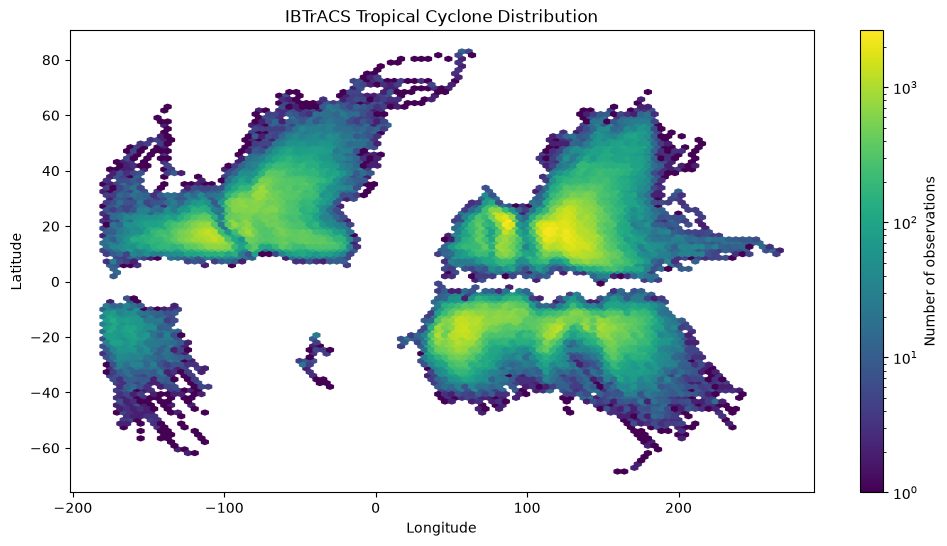

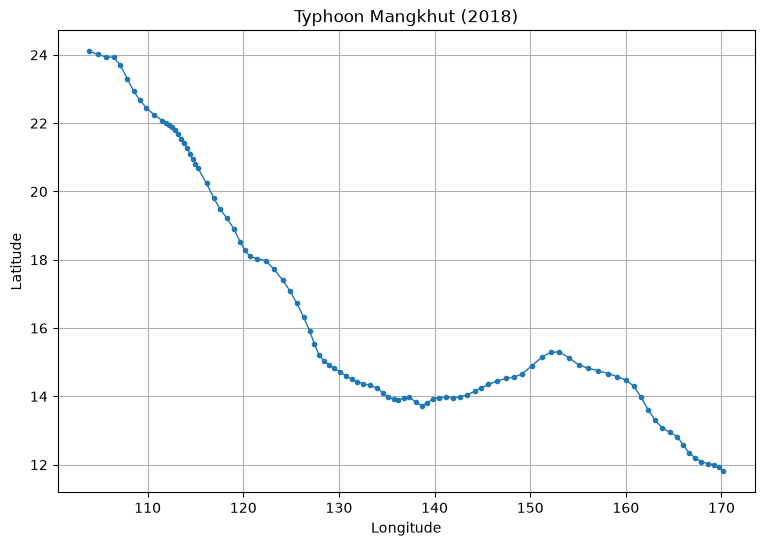

(176352, 17)


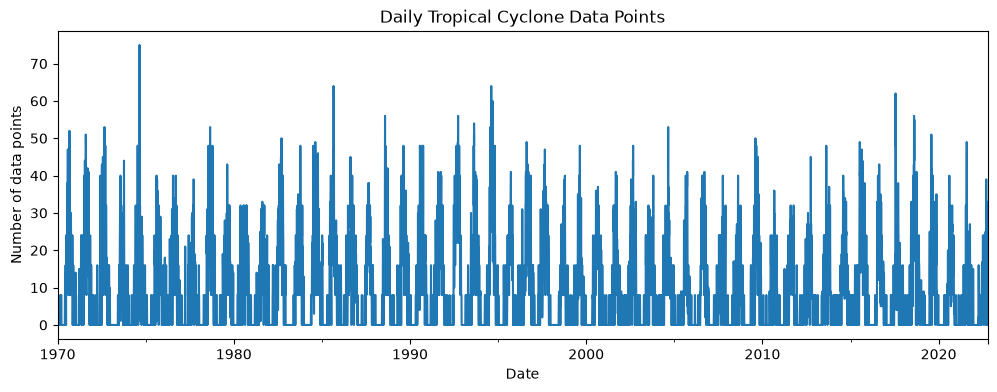

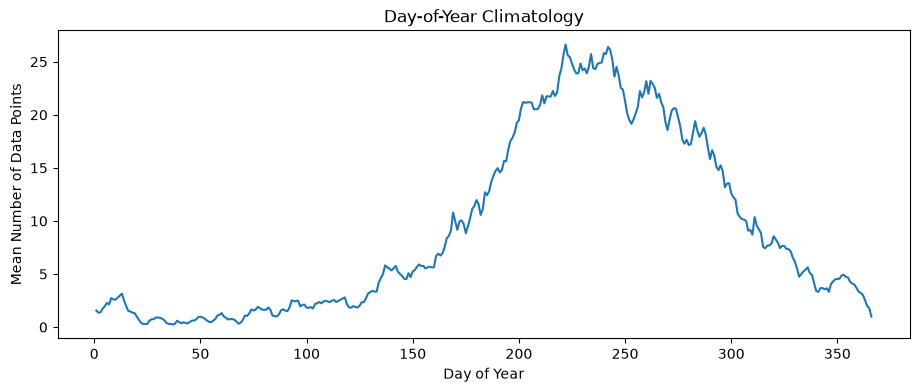

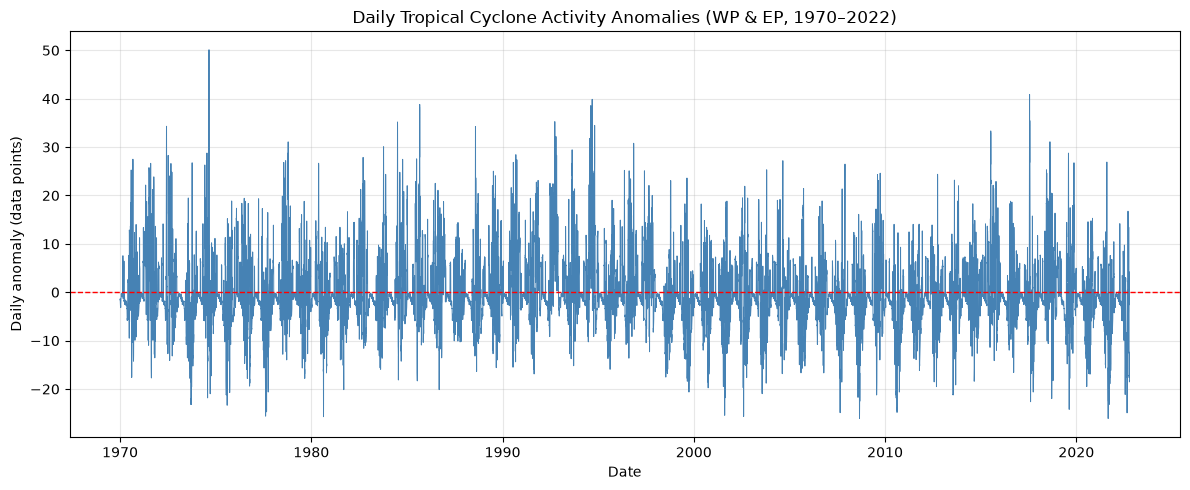

Index type: <class 'pandas.DatetimeIndex'>


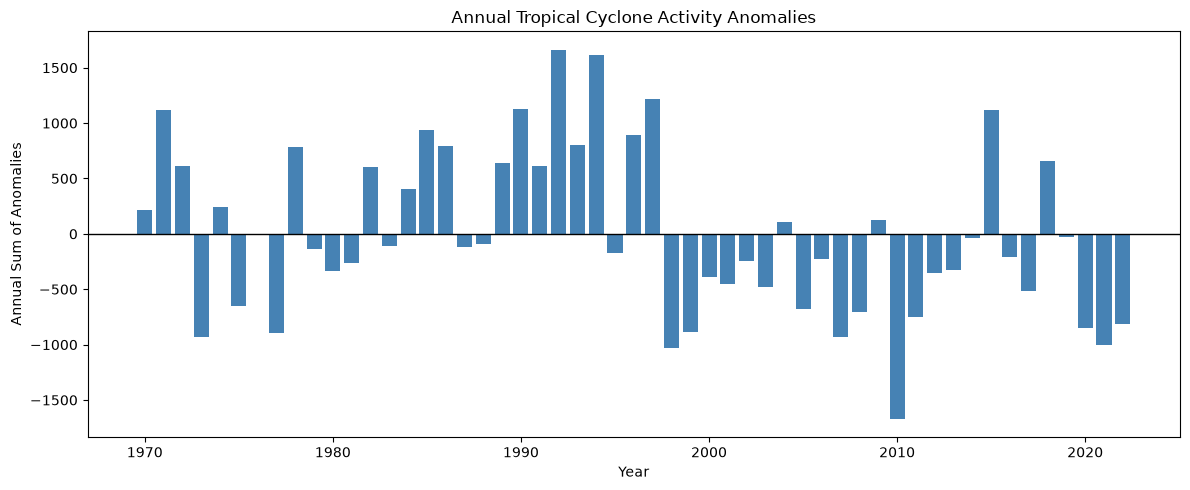

In [55]:
#3.1同一场热带气旋通常有多条轨迹观测记录，因此不能简单对整张表按风速排序，否则同一场风暴可能占据多个排名。正确做法是先使用SID分组，计算每场风暴的最大WMO_WIND，然后排序。
#3.1按风暴SID分组，获取最大风速和名称
top10 = (df.groupby("SID").agg(NAME=("NAME", "first"),WMO_WIND=("WMO_WIND", "max")).sort_values("WMO_WIND", ascending=False).head(10).reset_index())

print(top10)

#3.2列出最大风速排名前20的飓风名称
top20 = (df.groupby("SID").agg(NAME=("NAME", "first"),WMO_WIND=("WMO_WIND", "max")).sort_values("WMO_WIND", ascending=False).head(20).reset_index())

print(top20[["NAME", "WMO_WIND"]])

#3.3按流域统计所有数据点
basin_counts = (df.groupby("BASIN", dropna=False).size().sort_values(ascending=False))

print(basin_counts)

#3.4绘制一个六边形网格图，显示经纬度数据点的位置。画图相关的都还没学到，问AI加搜网上信息。
plt.figure(figsize=(12, 6))
plt.hexbin(df["LON"],df["LAT"],gridsize=100,bins="log",mincnt=1)
plt.colorbar(label="Number of observations")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("IBTrACS Tropical Cyclone Distribution")
plt.show()

#3.5查找2018年的台风“山竹”，并绘制其路径。
mangkhut = df.loc[(df["SEASON"] == 2018) &(df["NAME"] == "MANGKHUT")].copy()
mangkhut = mangkhut.sort_values("ISO_TIME")
plt.figure(figsize=(9, 6))
plt.plot(mangkhut["LON"],mangkhut["LAT"],marker=".",linewidth=1)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Typhoon Mangkhut (2018)")
plt.grid(True)
plt.show()

#3.6筛选1970年以来WP和EP海盆的数据
df_filtered = df.loc[(df["ISO_TIME"] >= "1970-01-01") &(df["BASIN"].isin(["WP", "EP"]))].copy()
print(df_filtered.shape)

#3.7绘制每日数据点数量的图表
df_filtered["Day"] = (df_filtered["ISO_TIME"].dt.normalize())
daily_counts = (df_filtered.groupby("Day").size())
# 创建完整日期序列
all_days = pd.date_range("1970-01-01",df["ISO_TIME"].max().normalize(),freq="D") #将日期时间归一化为当日零点
daily_counts = daily_counts.reindex(all_days, fill_value=0) #补齐没有轨迹观测的日期

daily_counts.plot(figsize=(12, 4))
plt.ylabel("Number of data points")
plt.xlabel("Date")
plt.title("Daily Tropical Cyclone Data Points")
plt.show()

#3.8计算数据点计数的年候学特征，并将其作为“年内第几天”的函数。所谓“年内第几天”，是指从1月1日（第1天）开始的连续天数。
daily = daily_counts.to_frame(name="Count")
# 计算年内第几天
daily["DayOfYear"] = daily.index.dayofyear
# 按年内日序计算多年平均
climatology = (daily.groupby("DayOfYear")["Count"].mean())

climatology.plot(figsize=(11, 4))
plt.xlabel("Day of Year")
plt.ylabel("Mean Number of Data Points")
plt.title("Day-of-Year Climatology")
plt.show()

#3.9计算每日数据点数量异常值。每日异常值定义为：当天观测点数量减去对应年内日序的多年平均数量。
daily["Climatology"] = (daily["DayOfYear"].map(climatology))
daily["Anomaly"] = (daily["Count"] - daily["Climatology"])

plt.figure(figsize=(12, 5))
plt.plot(daily.index,daily["Anomaly"],linewidth=0.7,color="steelblue")
plt.axhline(y=0,color="red",linestyle="--",linewidth=1)
plt.xlabel("Date")
plt.ylabel("Daily anomaly (data points)")
plt.title("Daily Tropical Cyclone Activity Anomalies (WP & EP, 1970–2022)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#3.10将每日异常重采样为年度，并识别异常年份

daily_new = daily.copy()
if isinstance(daily_new.index, pd.PeriodIndex):
    daily_new.index = daily_new.index.to_timestamp()

daily_new.index = pd.to_datetime(daily_new.index)

print("Index type:", type(daily_new.index))

annual_anomaly = (
    daily_new["Anomaly"]
    .resample("YS")
    .sum()
)

plt.figure(figsize=(12, 5))

plt.bar(
    annual_anomaly.index.year,
    annual_anomaly.values,
    color="steelblue"
)

plt.axhline(0, color="black", linewidth=1)

plt.xlabel("Year")
plt.ylabel("Annual Sum of Anomalies")
plt.title("Annual Tropical Cyclone Activity Anomalies")

plt.tight_layout()
plt.show()

原始月份数: 369
无效月份数: 14
清洗后有效月份数: 355


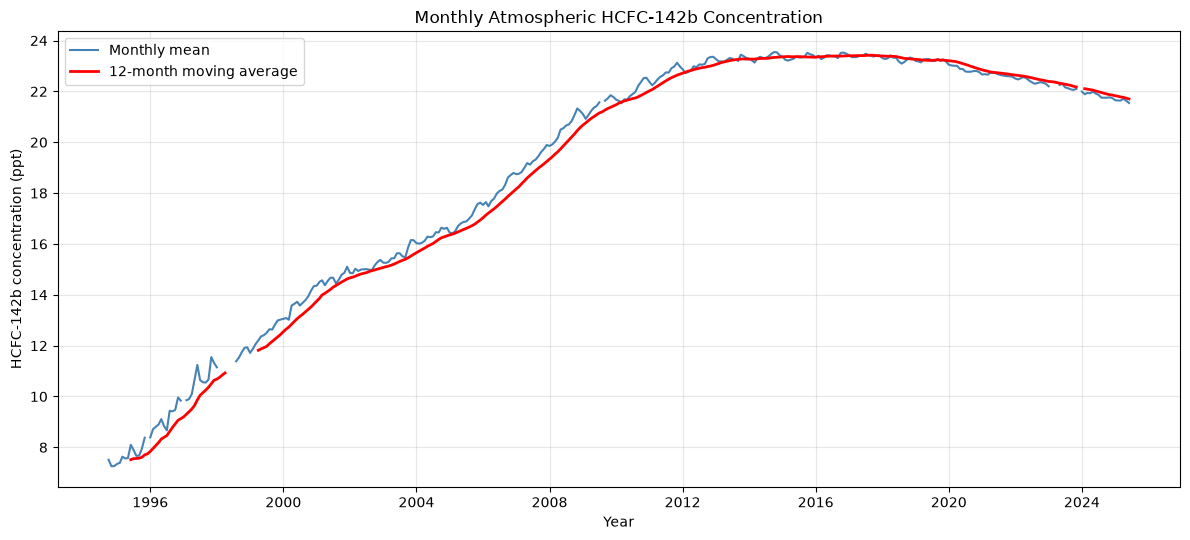

均值: 18.932631941408452
中位数: 21.649996
标准差: 4.890876201999363
最小值: 7.257316
最大值: 23.546812
25%分位数: 15.210446000000001
75%分位数: 23.054652
变异系数 (%): 25.83304961051029
年变化斜率: 0.497949610468838
决定系数 R²: 0.7949174697148306
回归显著性 p 值: 1.7087510824081868e-123
Kendall tau: 0.6610169491525423
Kendall p 值: 3.864835520650963e-77
Shapiro-Wilk W: 0.8329699885202385
Shapiro-Wilk p 值: 6.473535339353783e-19
ADF统计量: -2.7811543817221005
ADF p值: 0.06101656326544827
最初12个有效月份均值: 7.573795808333333
最后12个有效月份均值: 21.703214499999998
浓度差值: 14.129418691666665


In [65]:
#4本次选择的数据集为爱尔兰Mace Head观测站的HCFC-142b月度背景浓度数据。HCFC-142b属于氢氯氟烃（HCFCs）
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# 读取数据
df = pd.read_csv(
    "AGAGE_HCFC142b_monthly_raw_export.csv",
    encoding="utf-8-sig"
)

# 日期和数值类型转换
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

num_cols = [
    "HCFC142b_ppt", "SE_ppt",
    "SD_ppt", "N_Observations", "Instrument_Type"
]

for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 去除无效日期、重复日期，按日期排列
df = df.dropna(subset=["Date"])
df = df.drop_duplicates(subset=["Date"])
df = df.sort_values("Date").set_index("Date")

# 建立完整的月度索引
df = df.asfreq("MS")

# 质量控制条件
bad = (
    df["HCFC142b_ppt"].isna()
    | (df["HCFC142b_ppt"] <= 0)
    | (df["N_Observations"] < 10)
    | (df["SE_ppt"] < 0)
    | (df["SD_ppt"] < 0)
    | (~df["Instrument_Type"].isin([4, 5, 6]))
)

# 无效观测标记为 NaN
df["HCFC142b_clean"] = df["HCFC142b_ppt"].mask(bad)

# 提取有效数据
valid = df["HCFC142b_clean"].dropna()

print("原始月份数:", len(df))
print("无效月份数:", bad.sum())
print("清洗后有效月份数:", len(valid))

# 导出清洗结果
df.to_csv("HCFC142b_cleaned.csv", encoding="utf-8-sig")

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5.5))

# 月平均浓度
plt.plot(
    df.index,
    df["HCFC142b_clean"],
    color="steelblue",
    linewidth=1.5,
    label="Monthly mean"
)

# 12个月移动平均
rolling_mean = (
    df["HCFC142b_clean"]
    .rolling(window=12, min_periods=9)
    .mean()
)

plt.plot(
    df.index,
    rolling_mean,
    color="red",
    linewidth=2,
    label="12-month moving average"
)

plt.xlabel("Year")
plt.ylabel("HCFC-142b concentration (ppt)")
plt.title("Monthly Atmospheric HCFC-142b Concentration")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("HCFC142b_time_series.png", dpi=300)
plt.show()

from scipy import stats
from statsmodels.tsa.stattools import adfuller

# 有效浓度数据
y = valid.to_numpy()

# 1. 描述性统计
print("均值:", valid.mean())
print("中位数:", valid.median())
print("标准差:", valid.std())
print("最小值:", valid.min())
print("最大值:", valid.max())
print("25%分位数:", valid.quantile(0.25))
print("75%分位数:", valid.quantile(0.75))

# 2. 变异系数
cv = valid.std() / valid.mean() * 100
print("变异系数 (%):", cv)

# 3. 线性趋势检验
x = (valid.index - valid.index.min()).days / 365.25
slope, intercept, r, p, se = stats.linregress(x, y)

print("年变化斜率:", slope)
print("决定系数 R²:", r**2)
print("回归显著性 p 值:", p)

# 4. Kendall 趋势检验
tau, p_kendall = stats.kendalltau(x, y)
print("Kendall tau:", tau)
print("Kendall p 值:", p_kendall)

# 5. Shapiro-Wilk 正态性检验
W, p_normal = stats.shapiro(y)
print("Shapiro-Wilk W:", W)
print("Shapiro-Wilk p 值:", p_normal)

# 6. ADF 平稳性检验
# 仅为ADF检验建立等时间间隔的插值序列
adf_series = df["HCFC142b_clean"].interpolate(
    method="time",
    limit_direction="both"
)

adf_result = adfuller(adf_series, autolag="AIC")
print("ADF统计量:", adf_result[0])
print("ADF p值:", adf_result[1])

# 7. 首尾各12个有效月份的均值比较
first_mean = valid.iloc[:12].mean()
last_mean = valid.iloc[-12:].mean()

print("最初12个有效月份均值:", first_mean)
print("最后12个有效月份均值:", last_mean)
print("浓度差值:", last_mean - first_mean)